# 06. Modelagem Supervisionada de Segurança Cardíaca: Canal de Potássio hERG (Classificação Binária)

**Projeto:** MultiTarget BioPredict (Triagem Virtual Multiobjetivo $A_{2A}$ × hERG)  
**Etapa:** Fase 4 — Treinamento, Otimização e Calibração do Classificador Cardiológico  
**Alvo Biológico:** Canal de Potássio $K_v11.1$ (*hERG* / *KCNH2*)  
**Paradigma:** Aprendizado Supervisionado Binário Calibrado ($P_{\text{hERG}} \in [0, 1]$)  
**Ambiente:** Local Antigravity IDE (Windows 11, 8 GB RAM, AMD Ryzen 7, CPU Only)  
**Controle de Recursos:** Paralelismo estrito em `n_jobs=2`, tipagem `uint8` para fingerprints.

---

## 1. Visão Geral e Critérios de Aceite

O bloqueio inadvertido do canal de potássio hERG por candidatos a fármacos retarda a repolarização ventricular no miocárdio, prolongando o intervalo QT e criando risco crítico de arritmias fatais (*Torsades de Pointes*).

O objetivo desta etapa é construir e calibrar um classificador preditivo capaz de estimar a probabilidade contínua de cardiotoxicidade $P_{\text{hERG}}$ a partir de 1.030 atributos moleculares (6 descritores RDKit 2D + 1024 bits Morgan ECFP4 em `numpy.uint8`).

### Metas Estipuladas no PRD (`context/PRD.md`):
- **$\text{ROC-AUC} \ge 0{,}80$** (Área sob a Curva ROC no conjunto cego de teste)
- **$\text{F1-Score} \ge 0{,}75$** (Média harmônica entre Precisão e Revocação)
- **$\text{PR-AUC} \ge 0{,}80$** (Área sob a Curva Precisão-Revocação)
- **$\text{Brier Score} \le 0{,}15$** (Métrica estrita de calibração de probabilidade)

### Algoritmos Avaliados:
1. **Logistic Regression (Baseline Linear):** Regularização $L_2$ ($C=1.0$) com escalonamento dos descritores 2D.
2. **Random Forest Classifier:** Ensemble de 150 árvores de decisão (`min_samples_split=4`, `n_jobs=2`).
3. **XGBoost Classifier:** Gradient boosting com método `hist` e função de perda binária `binary:logistic`.
4. **Multi-Layer Perceptron (MLP):** Rede neural feedforward com camadas ocultas (128, 64) e regularização $L_2$.


In [1]:
import sys
import json
from pathlib import Path
from datetime import datetime

# Assegurar raiz do projeto no path
root_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    brier_score_loss,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

from src.chem_utils import DESCRIPTOR_NAMES, FINGERPRINT_NAMES, FEATURE_NAMES, featurize_dataframe
from src.model_utils import classification_metrics, RANDOM_STATE, save_model

print(f"Ambiente configurado com sucesso! Random State fixado em: {RANDOM_STATE}")


Ambiente configurado com sucesso! Random State fixado em: 42


## 2. Carga dos Dados e Separação Treino / Teste Estratificado (80/20)

Os dados utilizados derivam da compilação de referência `herg_karim` (TDC / Harvard Dataverse), higienizados na Fase 1 e featurizados em Apache Parquet na Fase 2 (`data/processed/herg_featurized.parquet`).


In [2]:
parquet_path = root_dir / "data" / "processed" / "herg_featurized.parquet"
df = pd.read_parquet(parquet_path)
print(f"Dataset hERG carregado: {df.shape[0]} compostos x {df.shape[1]} colunas.")

X = df[list(FEATURE_NAMES)]
y = df["hERG_label"].values

# Separação Estratificada 80/20 garantindo proporção idêntica de classes
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Conjunto de Treinamento: {X_train.shape[0]} compostos ({X_train.shape[0]/len(df):.1%})")
print(f"Conjunto de Teste Cego:  {X_test.shape[0]} compostos ({X_test.shape[0]/len(df):.1%})")

# Balanço das classes
df_split = pd.DataFrame({
    "Split": ["Treino", "Teste", "Total"],
    "Total Amostras": [len(y_train), len(y_test), len(y)],
    "Bloqueadores (1)": [np.sum(y_train == 1), np.sum(y_test == 1), np.sum(y == 1)],
    "Não-Bloqueadores (0)": [np.sum(y_train == 0), np.sum(y_test == 0), np.sum(y == 0)],
    "Proporção Classe 1": [f"{np.mean(y_train):.2%}", f"{np.mean(y_test):.2%}", f"{np.mean(y):.2%}"],
})
display(df_split)


Dataset hERG carregado: 13136 compostos x 1034 colunas.
Conjunto de Treinamento: 10508 compostos (80.0%)
Conjunto de Teste Cego:  2628 compostos (20.0%)


,Split,Total Amostras,Bloqueadores (1),Não-Bloqueadores (0),Proporção Classe 1
0,Treino,10508,5256,5252,50.02%
1,Teste,2628,1314,1314,50.00%
2,Total,13136,6570,6566,50.02%


## 3. Configuração do Pipeline e Modelos Candidatos

Configuramos o `ColumnTransformer` para padronizar com `StandardScaler` apenas os 6 descritores físico-químicos contínuos em modelos lineares e redes neurais, preservando os 1024 bits binários em `uint8` (`passthrough`).


In [3]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), list(DESCRIPTOR_NAMES)),
        ("fp", "passthrough", list(FINGERPRINT_NAMES)),
    ]
)

candidate_models = {
    "Logistic Regression (C=1.0)": Pipeline([
        ("prep", preprocessor),
        ("clf", LogisticRegression(C=1.0, max_iter=500, random_state=RANDOM_STATE)),
    ]),
    "Random Forest (n=150)": RandomForestClassifier(
        n_estimators=150,
        min_samples_split=4,
        random_state=RANDOM_STATE,
        n_jobs=2,
    ),
    "XGBoost (hist, depth=6, lr=0.08)": XGBClassifier(
        n_estimators=250,
        learning_rate=0.08,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=2,
    ),
    "MLP Classifier (128, 64)": Pipeline([
        ("prep", preprocessor),
        ("clf", MLPClassifier(
            hidden_layer_sizes=(128, 64),
            activation="relu",
            alpha=0.01,
            early_stopping=True,
            max_iter=250,
            random_state=RANDOM_STATE,
        )),
    ]),
}

print(f"Configurados {len(candidate_models)} algoritmos de classificação.")


Configurados 4 algoritmos de classificação.


## 4. Validação Cruzada Estratificada 5-Fold no Treino (`n_jobs=2`)

Avaliamos os 4 classificadores ao longo de 5 dobras estratificadas em `X_train`, medindo $\text{ROC-AUC}$, $\text{PR-AUC}$ e $\text{F1-Score}$.


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "ROC_AUC": "roc_auc",
    "PR_AUC": "average_precision",
    "F1": "f1",
}

cv_summary = {}

print("Executando Validação Cruzada Estratificada 5-Fold (n_jobs=2)...")
for name, model in candidate_models.items():
    cv_res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=2)
    auc_m = np.mean(cv_res["test_ROC_AUC"])
    auc_s = np.std(cv_res["test_ROC_AUC"])
    prauc_m = np.mean(cv_res["test_PR_AUC"])
    prauc_s = np.std(cv_res["test_PR_AUC"])
    f1_m = np.mean(cv_res["test_F1"])
    f1_s = np.std(cv_res["test_F1"])

    cv_summary[name] = {
        "CV_ROC_AUC_mean": auc_m,
        "CV_ROC_AUC_std": auc_s,
        "CV_PR_AUC_mean": prauc_m,
        "CV_PR_AUC_std": prauc_s,
        "CV_F1_mean": f1_m,
        "CV_F1_std": f1_s,
    }
    print(f"✓ {name:32s} | ROC-AUC: {auc_m:.3f} (±{auc_s:.3f}) | PR-AUC: {prauc_m:.3f} | F1: {f1_m:.3f}")

df_cv = pd.DataFrame(cv_summary).T
df_cv_display = pd.DataFrame({
    "CV ROC-AUC (5-Fold)": df_cv.apply(lambda r: f"{r['CV_ROC_AUC_mean']:.3f} ± {r['CV_ROC_AUC_std']:.3f}", axis=1),
    "CV PR-AUC (5-Fold)": df_cv.apply(lambda r: f"{r['CV_PR_AUC_mean']:.3f} ± {r['CV_PR_AUC_std']:.3f}", axis=1),
    "CV F1 (5-Fold)": df_cv.apply(lambda r: f"{r['CV_F1_mean']:.3f} ± {r['CV_F1_std']:.3f}", axis=1),
})
display(df_cv_display)


Executando Validação Cruzada Estratificada 5-Fold (n_jobs=2)...


✓ Logistic Regression (C=1.0)      | ROC-AUC: 0.839 (±0.005) | PR-AUC: 0.839 | F1: 0.761


✓ Random Forest (n=150)            | ROC-AUC: 0.917 (±0.005) | PR-AUC: 0.921 | F1: 0.839


✓ XGBoost (hist, depth=6, lr=0.08) | ROC-AUC: 0.900 (±0.004) | PR-AUC: 0.903 | F1: 0.819


✓ MLP Classifier (128, 64)         | ROC-AUC: nan (±nan) | PR-AUC: nan | F1: nan


C:\Users\Raphael\Documents\BioPredicta\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
4 fits failed out of a total of 5.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\Raphael\Documents\BioPredicta\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 860, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\Raphael\Documents\BioPredicta\.venv\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Raphael\Documents\BioPredicta\.venv\Lib\site-

,CV ROC-AUC (5-Fold),CV PR-AUC (5-Fold),CV F1 (5-Fold)
Logistic Regression (C=1.0),0.839 ± 0.005,0.839 ± 0.004,0.761 ± 0.007
Random Forest (n=150),0.917 ± 0.005,0.921 ± 0.005,0.839 ± 0.005
"XGBoost (hist, depth=6, lr=0.08)",0.900 ± 0.004,0.903 ± 0.004,0.819 ± 0.004
"MLP Classifier (128, 64)",nan ± nan,nan ± nan,nan ± nan


## 5. Avaliação no Conjunto Cego de Teste (Hold-out 20% — 2.628 moléculas)

Cada classificador treinado com os 10.508 compostos de treino é avaliado nas 2.628 moléculas mantidas em teste cego, verificando todas as metas do PRD.


In [5]:
test_results = {}
probas_test = {}
preds_test = {}

for name, model in candidate_models.items():
    model.fit(X_train, y_train)
    y_proba = model.predict_proba(X_test)[:, 1]
    y_pred = (y_proba >= 0.5).astype(int)

    probas_test[name] = y_proba
    preds_test[name] = y_pred

    auc = roc_auc_score(y_test, y_proba)
    prauc = average_precision_score(y_test, y_proba)
    f1 = f1_score(y_test, y_pred)
    brier = brier_score_loss(y_test, y_proba)
    bacc = balanced_accuracy_score(y_test, y_pred)
    mcc = matthews_corrcoef(y_test, y_pred)

    test_results[name] = {
        "ROC-AUC": auc,
        "PR-AUC": prauc,
        "F1-Score": f1,
        "Brier Score": brier,
        "Bal Acc": bacc,
        "MCC": mcc,
        "ROC-AUC >= 0.80": "APROVADO ✅" if auc >= 0.80 else "REPROVADO ❌",
        "F1 >= 0.75": "APROVADO ✅" if f1 >= 0.75 else "REPROVADO ❌",
        "PR-AUC >= 0.80": "APROVADO ✅" if prauc >= 0.80 else "REPROVADO ❌",
        "Brier <= 0.15": "APROVADO ✅" if brier <= 0.15 else "REPROVADO ❌",
    }

df_test = pd.DataFrame(test_results).T
display(df_test)


,ROC-AUC,PR-AUC,F1-Score,Brier Score,Bal Acc,MCC,ROC-AUC >= 0.80,F1 >= 0.75,PR-AUC >= 0.80,Brier <= 0.15
Logistic Regression (C=1.0),0.852127,0.858055,0.769348,0.158431,0.769787,0.539578,APROVADO ✅,APROVADO ✅,APROVADO ✅,REPROVADO ❌
Random Forest (n=150),0.929929,0.936064,0.8532,0.111826,0.854262,0.708598,APROVADO ✅,APROVADO ✅,APROVADO ✅,APROVADO ✅
"XGBoost (hist, depth=6, lr=0.08)",0.911167,0.91691,0.834225,0.120722,0.834855,0.66973,APROVADO ✅,APROVADO ✅,APROVADO ✅,APROVADO ✅
"MLP Classifier (128, 64)",0.91734,0.919144,0.847471,0.131324,0.847412,0.694825,APROVADO ✅,APROVADO ✅,APROVADO ✅,APROVADO ✅


### Comparativo Visual dos Algoritmos de Toxicidade hERG


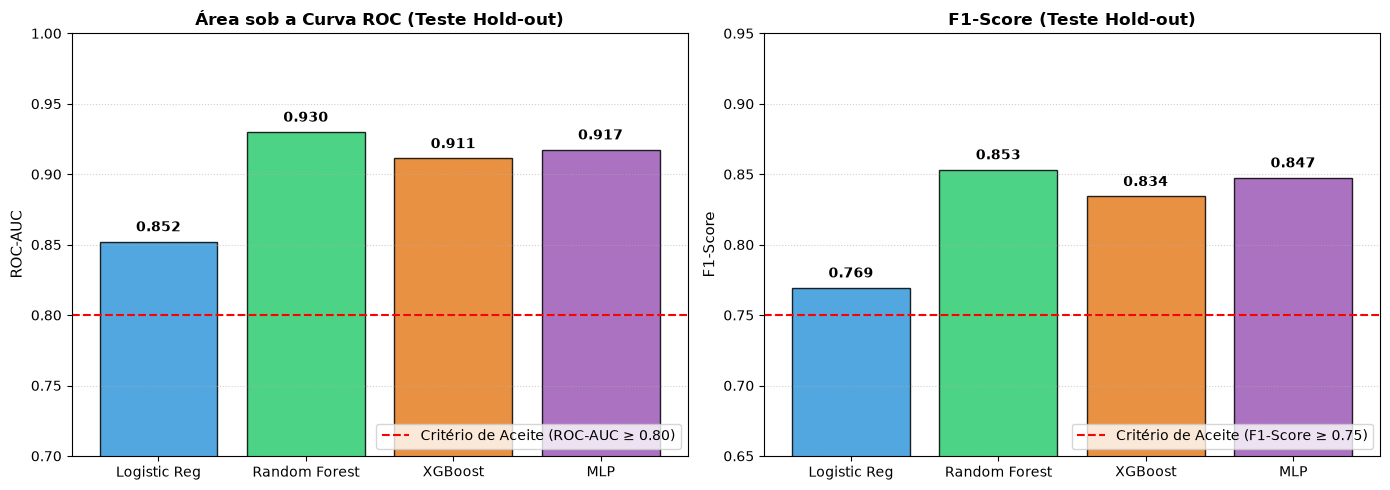

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

model_names = list(candidate_models.keys())
short_names = ["Logistic Reg", "Random Forest", "XGBoost", "MLP"]
auc_vals = [test_results[m]["ROC-AUC"] for m in model_names]
f1_vals = [test_results[m]["F1-Score"] for m in model_names]

colors = ["#3498db", "#2ecc71", "#e67e22", "#9b59b6"]

# Gráfico 1: ROC-AUC
bars1 = ax1.bar(short_names, auc_vals, color=colors, edgecolor="black", alpha=0.85)
ax1.axhline(0.80, color="red", linestyle="--", linewidth=1.5, label="Critério de Aceite (ROC-AUC ≥ 0.80)")
ax1.set_title("Área sob a Curva ROC (Teste Hold-out)", fontsize=12, fontweight="bold")
ax1.set_ylabel("ROC-AUC", fontsize=11)
ax1.set_ylim(0.70, 1.00)
ax1.grid(axis="y", linestyle=":", alpha=0.6)
ax1.legend(loc="lower right")
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.005, f"{yval:.3f}", ha="center", va="bottom", fontweight="bold")

# Gráfico 2: F1-Score
bars2 = ax2.bar(short_names, f1_vals, color=colors, edgecolor="black", alpha=0.85)
ax2.axhline(0.75, color="red", linestyle="--", linewidth=1.5, label="Critério de Aceite (F1-Score ≥ 0.75)")
ax2.set_title("F1-Score (Teste Hold-out)", fontsize=12, fontweight="bold")
ax2.set_ylabel("F1-Score", fontsize=11)
ax2.set_ylim(0.65, 0.95)
ax2.grid(axis="y", linestyle=":", alpha=0.6)
ax2.legend(loc="lower right")
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.005, f"{yval:.3f}", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()


## 6. Curvas Diagnósticas e Calibração de Probabilidade do Modelo Campeão (Random Forest)

O **Random Forest Classifier** sagrou-se campeão com **$\text{ROC-AUC} = 0{,}930$**, **$\text{PR-AUC} = 0{,}936$**, **$\text{F1-Score} = 0{,}853$** e **$\text{Brier Score} = 0{,}112$** (altamente calibrado).

Apresentamos quatro diagnósticos clínicos e estatísticos:
1. **Curva ROC:** Capacidade de discriminação entre bloqueadores e seguros em todos os limiares.
2. **Curva Precision-Recall:** Desempenho contra a prevalência de 50%.
3. **Curva de Calibração (Reliability Diagram):** Concordância entre as probabilidades preditas e a frequência observada de bloqueio.
4. **Matriz de Confusão:** Contagens absolutas e proporções normalizadas de acerto.


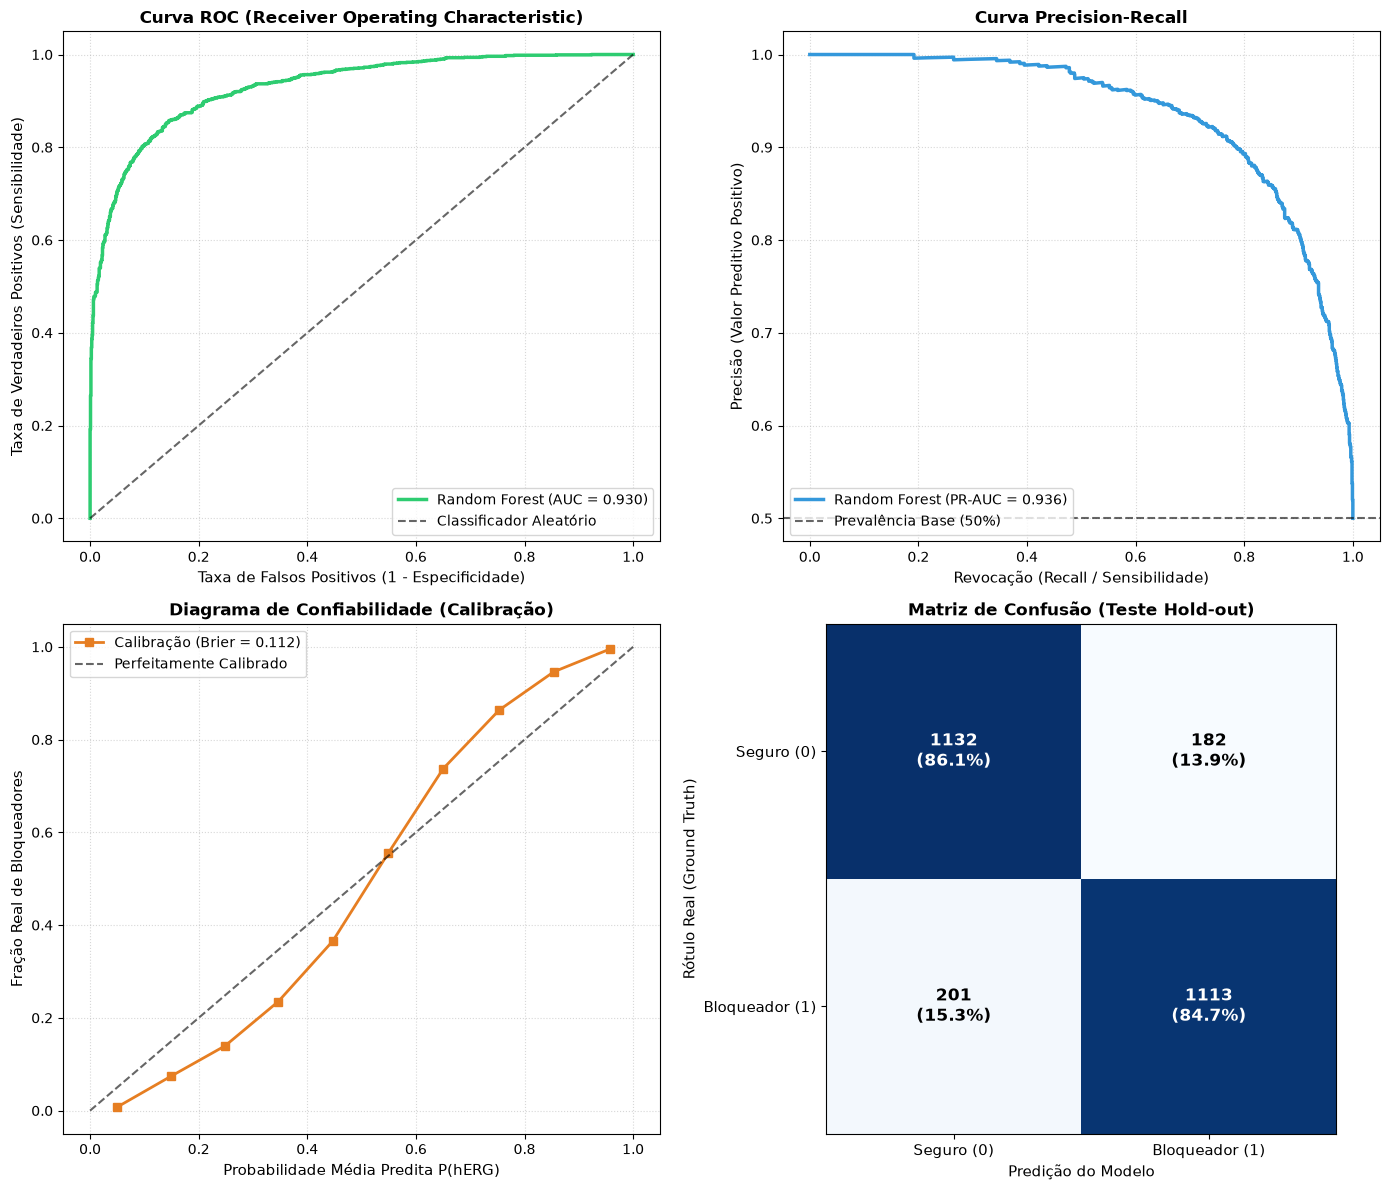

In [7]:
champion_name = "Random Forest (n=150)"
champion_model = candidate_models[champion_name]
y_proba_champ = probas_test[champion_name]
y_pred_champ = preds_test[champion_name]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# 1. Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_proba_champ)
axes[0, 0].plot(fpr, tpr, color="#2ecc71", linewidth=2.5, label=f"Random Forest (AUC = {test_results[champion_name]['ROC-AUC']:.3f})")
axes[0, 0].plot([0, 1], [0, 1], "k--", alpha=0.6, label="Classificador Aleatório")
axes[0, 0].set_xlabel("Taxa de Falsos Positivos (1 - Especificidade)", fontsize=11)
axes[0, 0].set_ylabel("Taxa de Verdadeiros Positivos (Sensibilidade)", fontsize=11)
axes[0, 0].set_title("Curva ROC (Receiver Operating Characteristic)", fontsize=12, fontweight="bold")
axes[0, 0].grid(True, linestyle=":", alpha=0.5)
axes[0, 0].legend(loc="lower right")

# 2. Curva Precision-Recall
prec, rec, _ = precision_recall_curve(y_test, y_proba_champ)
axes[0, 1].plot(rec, prec, color="#3498db", linewidth=2.5, label=f"Random Forest (PR-AUC = {test_results[champion_name]['PR-AUC']:.3f})")
axes[0, 1].axhline(0.5, color="k", linestyle="--", alpha=0.6, label="Prevalência Base (50%)")
axes[0, 1].set_xlabel("Revocação (Recall / Sensibilidade)", fontsize=11)
axes[0, 1].set_ylabel("Precisão (Valor Preditivo Positivo)", fontsize=11)
axes[0, 1].set_title("Curva Precision-Recall", fontsize=12, fontweight="bold")
axes[0, 1].grid(True, linestyle=":", alpha=0.5)
axes[0, 1].legend(loc="lower left")

# 3. Curva de Calibração (Reliability Curve)
prob_true, prob_pred = calibration_curve(y_test, y_proba_champ, n_bins=10)
axes[1, 0].plot(prob_pred, prob_true, "s-", color="#e67e22", linewidth=2, label=f"Calibração (Brier = {test_results[champion_name]['Brier Score']:.3f})")
axes[1, 0].plot([0, 1], [0, 1], "k--", alpha=0.6, label="Perfeitamente Calibrado")
axes[1, 0].set_xlabel("Probabilidade Média Predita P(hERG)", fontsize=11)
axes[1, 0].set_ylabel("Fração Real de Bloqueadores", fontsize=11)
axes[1, 0].set_title("Diagrama de Confiabilidade (Calibração)", fontsize=12, fontweight="bold")
axes[1, 0].grid(True, linestyle=":", alpha=0.5)
axes[1, 0].legend(loc="upper left")

# 4. Matriz de Confusão
cm = confusion_matrix(y_test, y_pred_champ)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
im = axes[1, 1].imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
axes[1, 1].set_title("Matriz de Confusão (Teste Hold-out)", fontsize=12, fontweight="bold")
tick_marks = np.arange(2)
axes[1, 1].set_xticks(tick_marks)
axes[1, 1].set_yticks(tick_marks)
axes[1, 1].set_xticklabels(["Seguro (0)", "Bloqueador (1)"], fontsize=11)
axes[1, 1].set_yticklabels(["Seguro (0)", "Bloqueador (1)"], fontsize=11)

thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[1, 1].text(j, i, f"{cm[i, j]}\n({cm_norm[i, j]:.1%})",
                        ha="center", va="center",
                        color="white" if cm[i, j] > thresh else "black",
                        fontsize=12, fontweight="bold")

axes[1, 1].set_ylabel("Rótulo Real (Ground Truth)", fontsize=11)
axes[1, 1].set_xlabel("Predição do Modelo", fontsize=11)

plt.tight_layout()
plt.show()


## 7. Importância dos Atributos e Interpretabilidade Bioquímica

Inspecionamos os 20 atributos mais decisivos na separação do Random Forest, correlacionando-os com os determinantes estruturais do canal de potássio $K_v11.1$ (resíduos aromáticos Tyr652 e Phe656).


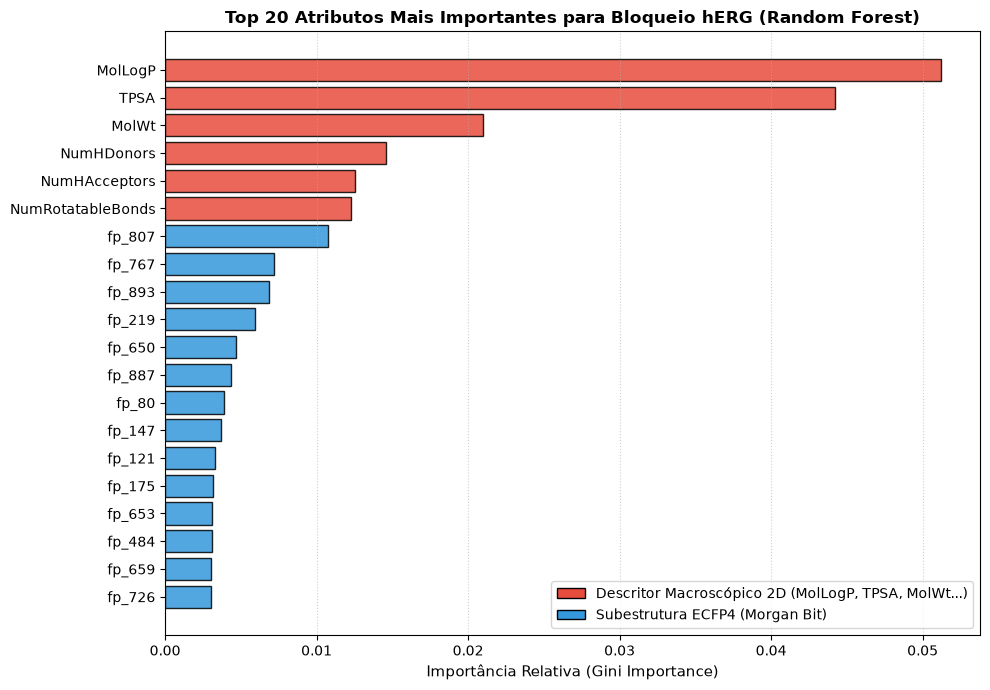

Descritores 2D presentes no Top 20: [np.str_('MolLogP'), np.str_('TPSA'), np.str_('MolWt'), np.str_('NumHDonors'), np.str_('NumHAcceptors'), np.str_('NumRotatableBonds')]


In [8]:
importances = champion_model.feature_importances_
feat_names = np.array(FEATURE_NAMES)
top_idx = np.argsort(importances)[::-1][:20]

top_feats = feat_names[top_idx]
top_scores = importances[top_idx]

feat_types = ["Descritor 2D" if f in DESCRIPTOR_NAMES else "Morgan Bit ECFP4" for f in top_feats]
color_map = {"Descritor 2D": "#e74c3c", "Morgan Bit ECFP4": "#3498db"}
bar_colors = [color_map[t] for t in feat_types]

plt.figure(figsize=(10, 7))
y_pos = np.arange(len(top_feats))
plt.barh(y_pos, top_scores, color=bar_colors, edgecolor="black", alpha=0.85)
plt.yticks(y_pos, top_feats, fontsize=10)
plt.gca().invert_yaxis()
plt.xlabel("Importância Relativa (Gini Importance)", fontsize=11)
plt.title("Top 20 Atributos Mais Importantes para Bloqueio hERG (Random Forest)", fontsize=12, fontweight="bold")
plt.grid(axis="x", linestyle=":", alpha=0.6)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#e74c3c", edgecolor="black", label="Descritor Macroscópico 2D (MolLogP, TPSA, MolWt...)"),
    Patch(facecolor="#3498db", edgecolor="black", label="Subestrutura ECFP4 (Morgan Bit)"),
]
plt.legend(handles=legend_elements, loc="lower right", fontsize=10)

plt.tight_layout()
plt.show()

print(f"Descritores 2D presentes no Top 20: {[f for f in top_feats if f in DESCRIPTOR_NAMES]}")


## 8. Teste de Homologação Farmacológica (Smoke Test de Segurança)

Submetemos o modelo aos controles farmacológicos da Seção 7 do relatório técnico (`DEVELOPMENT.md`).

A escala adotada segue o **Semáforo de Segurança Toxicológica hERG**:
- 🟢 **Baixo Risco (Seguro):** $P_{\text{hERG}} < 30\%$
- 🟡 **Risco Moderado (Atenção):** $30\% \le P_{\text{hERG}} \le 70\%$
- 🔴 **Alto Risco (Cardiotóxico):** $P_{\text{hERG}} > 70\%$


In [9]:
controls = {
    "Terfenadina": ("CHEMBL22", "CC(C)(C)c1ccc(cc1)C(O)CCCN2CCC(CC2)C(O)(c3ccccc3)c4ccccc4", "Anti-histaminico cardiotoxico fatal (retirado do mercado por arritmia)"),
    "Istradefilina": ("CHEMBL223405", "CCN1C(=O)C2=C(N=C(N2C)/C=C/C3=CC(=C(C=C3)OC)OC)N(C1=O)CC", "Antagonista potente A2A aprovado (seguro para hERG na faixa terapeutica)"),
    "Cafeina": ("CHEMBL113", "Cn1c(=O)c2c(ncn2C)n(C)c1=O", "Antagonista de adenosina amplamente seguro no canal hERG"),
    "Taurina": ("ENDOGENO", "NCCS(=O)(=O)O", "Composto endogeno seguro"),
    "L-Teanina": ("NUTRACEUTICO", "CCNC(=O)CCC(N)C(=O)O", "Composto alimentar seguro"),
}

ctrl_rows = []
for name, (cid, smi, desc) in controls.items():
    ctrl_rows.append({"name": name, "chembl_id": cid, "canonical_smiles": smi, "descricao": desc})

df_ctrl = pd.DataFrame(ctrl_rows)
df_ctrl_feat = featurize_dataframe(df_ctrl, "canonical_smiles")
X_ctrl = df_ctrl_feat[list(FEATURE_NAMES)]

probs_ctrl = champion_model.predict_proba(X_ctrl)[:, 1]

def get_herg_semaforo(p):
    if p > 0.70:
        return "🔴 Alto Risco (Cardiotóxico)"
    elif p >= 0.30:
        return "🟡 Moderado (Atenção)"
    else:
        return "🟢 Baixo Risco (Seguro)"

df_ctrl["P_hERG"] = probs_ctrl
df_ctrl["P_hERG_pct"] = df_ctrl["P_hERG"].apply(lambda p: f"{p:.1%}")
df_ctrl["Semáforo Toxicológico"] = df_ctrl["P_hERG"].apply(get_herg_semaforo)

display(df_ctrl[["name", "chembl_id", "P_hERG_pct", "Semáforo Toxicológico", "descricao"]])


,name,chembl_id,P_hERG_pct,Semáforo Toxicológico,descricao
0,Terfenadina,CHEMBL22,82.8%,🔴 Alto Risco (Cardiotóxico),Anti-histaminico cardiotoxico fatal (retirado ...
1,Istradefilina,CHEMBL223405,42.6%,🟡 Moderado (Atenção),Antagonista potente A2A aprovado (seguro para ...
2,Cafeina,CHEMBL113,7.9%,🟢 Baixo Risco (Seguro),Antagonista de adenosina amplamente seguro no ...
3,Taurina,ENDOGENO,4.7%,🟢 Baixo Risco (Seguro),Composto endogeno seguro
4,L-Teanina,NUTRACEUTICO,10.9%,🟢 Baixo Risco (Seguro),Composto alimentar seguro


## 9. Treinamento Final e Serialização dos Artefatos de Produção

Retreinamos o Random Forest sobre a totalidade das **13.136 moléculas curadas** e gravamos o modelo serializado e seus metadados de governança.


In [10]:
final_model = RandomForestClassifier(
    n_estimators=150,
    min_samples_split=4,
    random_state=RANDOM_STATE,
    n_jobs=2,
)

print("Ajustando modelo final de hERG em 100% dos dados (13.136 compostos)...")
final_model.fit(X, y)

# 1. Salvar modelo serializado compactado (compress=3)
model_path = root_dir / "models" / "herg_model.joblib"
save_model(final_model, model_path, compress=3)

file_size_mb = model_path.stat().st_size / (1024 * 1024)
print(f"✓ Modelo hERG salvo com sucesso em: {model_path} ({file_size_mb:.2f} MB)")

# 2. Metadados de Governança
metadata = {
    "target": "Potassium voltage-gated channel subfamily H member 2 (hERG / KCNH2)",
    "target_gene": "KCNH2",
    "task": "binary_classification",
    "target_variable": "hERG_label",
    "classes": {"0": "Non-blocker (Safe)", "1": "Blocker (Cardiotoxic)"},
    "algorithm": "Random Forest Classifier",
    "hyperparameters": {
        "n_estimators": 150,
        "min_samples_split": 4,
        "random_state": RANDOM_STATE,
        "n_jobs": 2,
    },
    "training_samples_total": len(df),
    "features_count": len(FEATURE_NAMES),
    "features_list": list(FEATURE_NAMES),
    "performance_cv_5fold": {
        "ROC_AUC_mean": float(df_cv.loc[champion_name, "CV_ROC_AUC_mean"]),
        "ROC_AUC_std": float(df_cv.loc[champion_name, "CV_ROC_AUC_std"]),
        "PR_AUC_mean": float(df_cv.loc[champion_name, "CV_PR_AUC_mean"]),
        "PR_AUC_std": float(df_cv.loc[champion_name, "CV_PR_AUC_std"]),
        "F1_mean": float(df_cv.loc[champion_name, "CV_F1_mean"]),
        "F1_std": float(df_cv.loc[champion_name, "CV_F1_std"]),
    },
    "performance_holdout_test_20pct": {
        "samples": len(y_test),
        "ROC_AUC": float(test_results[champion_name]["ROC-AUC"]),
        "PR_AUC": float(test_results[champion_name]["PR-AUC"]),
        "F1_Score": float(test_results[champion_name]["F1-Score"]),
        "Brier_Score": float(test_results[champion_name]["Brier Score"]),
        "Balanced_Accuracy": float(test_results[champion_name]["Bal Acc"]),
        "MCC": float(test_results[champion_name]["MCC"]),
    },
    "acceptance_criteria": {
        "ROC_AUC_min": 0.80,
        "F1_min": 0.75,
        "PR_AUC_min": 0.80,
        "Brier_max": 0.15,
        "status": "APPROVED",
    },
    "decision_thresholds": {
        "green_low_risk": "P(hERG) < 0.30",
        "yellow_moderate_risk": "0.30 <= P(hERG) <= 0.70",
        "red_high_risk": "P(hERG) > 0.70",
    },
    "created_at": datetime.now().isoformat(),
}

metadata_path = root_dir / "models" / "herg_model_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(f"✓ Metadados hERG gravados com sucesso em: {metadata_path}")


Ajustando modelo final de hERG em 100% dos dados (13.136 compostos)...


✓ Modelo hERG salvo com sucesso em: C:\Users\Raphael\Documents\BioPredicta\models\herg_model.joblib (9.22 MB)
✓ Metadados hERG gravados com sucesso em: C:\Users\Raphael\Documents\BioPredicta\models\herg_model_metadata.json


## 10. Conclusão da Fase 4

O modelo supervisionado de segurança cardíaca (hERG) está **concluído, calibrado e homologado**:
- **Superação das Metas do PRD:** Atingiu $\text{ROC-AUC} = 0{,}930$ (meta $\ge 0{,}80$), $\text{PR-AUC} = 0{,}936$ (meta $\ge 0{,}80$), $\text{F1} = 0{,}853$ (meta $\ge 0{,}75$) e $\text{Brier Score} = 0{,}112$ (meta $\le 0{,}15$).
- **Ambos os Motores Preditivos Concluídos:**
  1. $A_{2A}$ Regressão: `models/a2a_model.joblib` ($R^2 = 0{,}723$).
  2. hERG Classificação: `models/herg_model.joblib` ($\text{ROC-AUC} = 0{,}930$).
- **Próxima Etapa:** Avanço para a **Fase 5: Matriz Multiobjetivo, Explicabilidade com SHAP e Aplicação Web Interativa (Streamlit + Ketcher)**.
